In [88]:
# clustring
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler,OneHotEncoder
import pandas as pd

data=pd.read_csv("../data/customer-churn-clean.csv")
# print(data.shape)
# print(data.head())
# print(data.tail())


data_without_churn = data.drop(columns=["customerID", "Churn"])

numeric_column =[
    "SeniorCitizen",
    "tenure",
    "MonthlyCharges",
    "TotalCharges"
]

cate_column =[
    "gender",
    "Partner",
    "Dependents",
    "PhoneService",
    "MultipleLines",
    "InternetService",
    "OnlineSecurity",
    "OnlineBackup",
    "DeviceProtection",
    "TechSupport",
    "StreamingTV",
    "StreamingMovies",
    "Contract",
    "PaperlessBilling",
    "PaymentMethod"
]

print(data_without_churn.columns)

preprocessor=ColumnTransformer(
    transformers=[
        ("num",StandardScaler(),numeric_column),
        ("cat",OneHotEncoder(handle_unknown="ignore"),cate_column)
    ]
)

x_cluser=preprocessor.fit_transform(data_without_churn)

print(data_without_churn.shape)
print(x_cluser.shape)



Index(['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure',
       'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity',
       'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV',
       'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod',
       'MonthlyCharges', 'TotalCharges'],
      dtype='str')
(7043, 19)
(7043, 45)


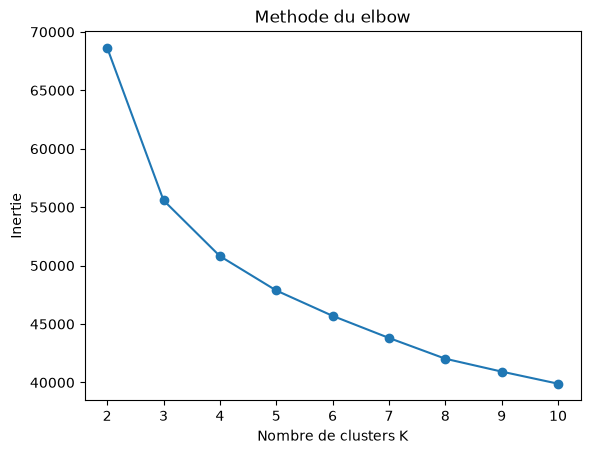

In [89]:
from  sklearn.cluster import KMeans
import matplotlib.pylab as plt

inertias=[]

for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10) 
    kmeans.fit(x_cluser)
    inertias.append(kmeans.inertia_)


# la partie visuel k =3

plt.plot(range(2,11),inertias,marker="o")
plt.xlabel("Nombre de clusters K")
plt.ylabel("Inertie")
plt.title("Methode du elbow")
plt.show()

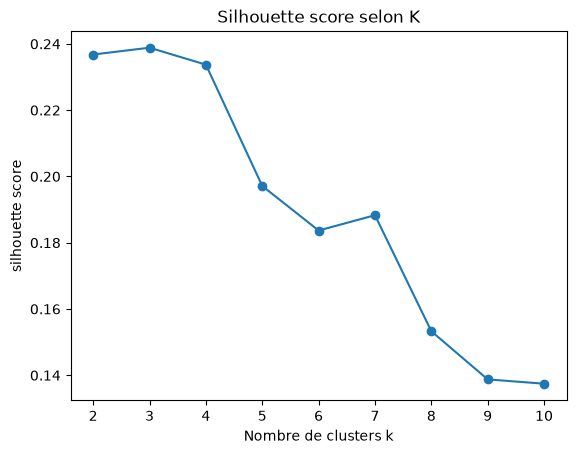

3


In [90]:
# la partie silhoitte score
from sklearn.metrics import silhouette_score # meure la qualite de la aseparation des clusers

silhouette_scores=[]
for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)

    labels=kmeans.fit_predict(x_cluser)#apprendre les clusters(cherche les k group)  + attribuer les point a un cluster => le numero du cluster de chque observation
    score=silhouette_score(x_cluser,labels)

    silhouette_scores.append(score)

    # print(f"k={k} silhouette score = {score:.3f}")



# visualisation
plt.plot(range(2,11),silhouette_scores,marker="o")

plt.xlabel("Nombre de clusters k")
plt.ylabel("silhouette score")
plt.title("Silhouette score selon K")
plt.show()


# the best one
# best=max(silhouette_scores)
# print(best)
best=range(2,11)[silhouette_scores.index(max(silhouette_scores))]
print(best)

In [91]:
# final entrainement 
kmeans=KMeans(
    n_clusters=best,
    random_state=42,
    n_init=10
)
clusters=kmeans.fit_predict(x_cluser)

# print(clusters)#le cluster de chque observation 

data["Cluster"]=clusters

# print(data.columns)

# print(data["Cluster"].value_counts().sort_index())

cluster_numeric=data.groupby("Cluster")[numeric_column].mean()
print(cluster_numeric)


# print(data["Cluster"].value_counts())


         SeniorCitizen     tenure  MonthlyCharges  TotalCharges
Cluster                                                        
0             0.034076  30.547182       21.079194    662.604784
1             0.195986  15.301662       67.862653   1018.083569
2             0.199742  56.949313       89.147659   5068.026332


In [92]:
# dbscan
from sklearn.cluster import DBSCAN

dbscan=DBSCAN(eps=0.5,min_samples=5)
dbscan_label=dbscan.fit_predict(x_cluser)
# print(dbscan_label)
print(pd.Series(dbscan_label).value_counts().sort_index())

-1      5746
 0        19
 1         7
 2        80
 3         8
        ... 
 110       5
 111       6
 112       5
 113       5
 114       5
Name: count, Length: 116, dtype: int64


In [93]:
import numpy as np

for eps in np.arange(2.0, 3.0, 0.1):
    labels=DBSCAN(eps=eps,min_samples=5).fit_predict(x_cluser)
    clusters=len(set(labels)) - (1 if -1 in labels else 0)
    bruit=np.sum(labels == -1)
    if clusters > 1:
        mask=labels != -1
        silhouette= silhouette_score(x_cluser[mask],labels[mask])
    else:
        silhouette=0
    
    print(f"eps = {eps:.1f} | clusters = {clusters} | bruit = {bruit} | silhouitte = {silhouette:.2f}")

eps = 2.0 | clusters = 29 | bruit = 1935 | silhouitte = -0.02
eps = 2.1 | clusters = 11 | bruit = 510 | silhouitte = 0.01
eps = 2.2 | clusters = 6 | bruit = 310 | silhouitte = 0.12
eps = 2.3 | clusters = 5 | bruit = 218 | silhouitte = 0.13
eps = 2.4 | clusters = 4 | bruit = 176 | silhouitte = 0.17
eps = 2.5 | clusters = 4 | bruit = 53 | silhouitte = 0.17
eps = 2.6 | clusters = 4 | bruit = 20 | silhouitte = 0.17
eps = 2.7 | clusters = 4 | bruit = 10 | silhouitte = 0.17
eps = 2.8 | clusters = 2 | bruit = 7 | silhouitte = 0.24
eps = 2.9 | clusters = 2 | bruit = 1 | silhouitte = 0.24


In [94]:
data["Cluster_dbscan"]=DBSCAN(eps=2.7,min_samples=5).fit_predict(x_cluser)

print(data[data["Cluster_dbscan"] != -1].groupby("Cluster_dbscan")[["SeniorCitizen", "tenure", "MonthlyCharges", "TotalCharges"]].mean().round(2))

                SeniorCitizen  tenure  MonthlyCharges  TotalCharges
Cluster_dbscan                                                     
0                         0.0   32.86           75.43       2684.43
1                         0.0   30.18           21.05        653.09
2                         1.0   32.88           82.79       2904.85
3                         1.0   41.10           21.90        932.30


In [95]:
# Davies-bouldin

from sklearn.metrics import davies_bouldin_score
db_scores=[]

for k in range(2,11):
    kmeans=KMeans(n_clusters=k,random_state=42,n_init=10)
    labels=kmeans.fit_predict(x_cluser)
    score=davies_bouldin_score(x_cluser,labels)

    db_scores.append(score)

    print(f"K={k} davies-bouldin={score:.3f}")

K=2 davies-bouldin=1.369
K=3 davies-bouldin=1.682
K=4 davies-bouldin=1.668
K=5 davies-bouldin=1.923
K=6 davies-bouldin=2.078
K=7 davies-bouldin=2.017
K=8 davies-bouldin=2.034
K=9 davies-bouldin=2.093
K=10 davies-bouldin=2.143


In [96]:
from sklearn.metrics import silhouette_score

labels_kmeans=data["Cluster"]

silhouette_kmeans=silhouette_score(x_cluser,labels_kmeans)
print("Silhouette kmeans :",silhouette_kmeans)


labels_dbscan = data["Cluster_dbscan"]

mask = labels_dbscan != -1

silhouette_dbscan = silhouette_score(
    x_cluser[mask],
    labels_dbscan[mask]
)

print("Silhouette DBSCAN :", silhouette_dbscan)

Silhouette kmeans : 0.23884693175576685
Silhouette DBSCAN : 0.17304238538160083


In [97]:
data.drop(columns=["Cluster_dbscan"],inplace=True)

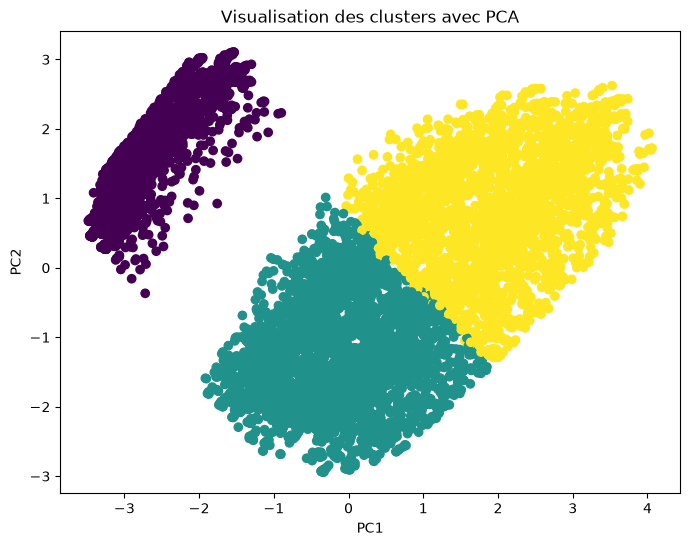

In [98]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

kmeans_final=KMeans(n_clusters=3,random_state=42,n_init=10)
labels_kmeans=kmeans_final.fit_predict(x_cluser)


pca = PCA(n_components=2)

x_pca = pca.fit_transform(x_cluser)


plt.figure(figsize=(8, 6))

plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=labels_kmeans
)

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Visualisation des clusters avec PCA")
plt.show()

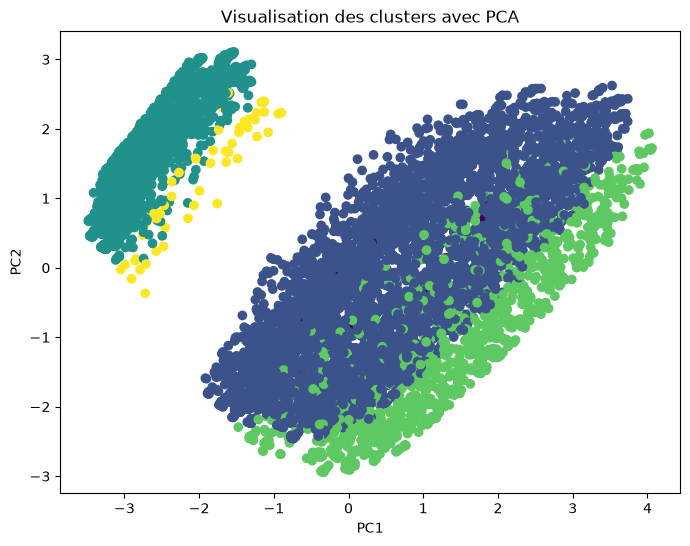

In [99]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

dbscan_final = DBSCAN(eps=2.7, min_samples=5)

labels_dbscan = dbscan_final.fit_predict(x_cluser)

plt.figure(figsize=(8, 6))

plt.scatter(
    x_pca[:, 0],
    x_pca[:, 1],
    c=labels_dbscan
)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("Visualisation des clusters avec PCA")
plt.show()

In [100]:
data.to_csv(
    "../data/customer-churn-clustered.csv",
    index=False
)

In [103]:
import joblib
joblib.dump(preprocessor, "../models/cluster_preprocessor.pkl")
joblib.dump(kmeans_final, "../models/kmeans_model.pkl")

['../models/kmeans_model.pkl']